In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from src.models.churn_models import load_data, walk_forward, summarize

sns.set_theme(style="whitegrid")
data = load_data()
results, preds = walk_forward(data)
summarize(results)

,pr_auc,roc_auc,precision_top10,recall_top10,brier,base_rate,lift_top10
model,,,,,,,
recency baseline,0.680,0.674,0.755,0.143,NaN,0.533,1.418
logistic regression,0.764,0.779,0.835,0.159,0.207,0.533,1.568
xgboost,0.752,0.767,0.813,0.155,0.214,0.533,1.526
xgboost + month,0.761,0.772,0.836,0.159,0.218,0.533,1.569


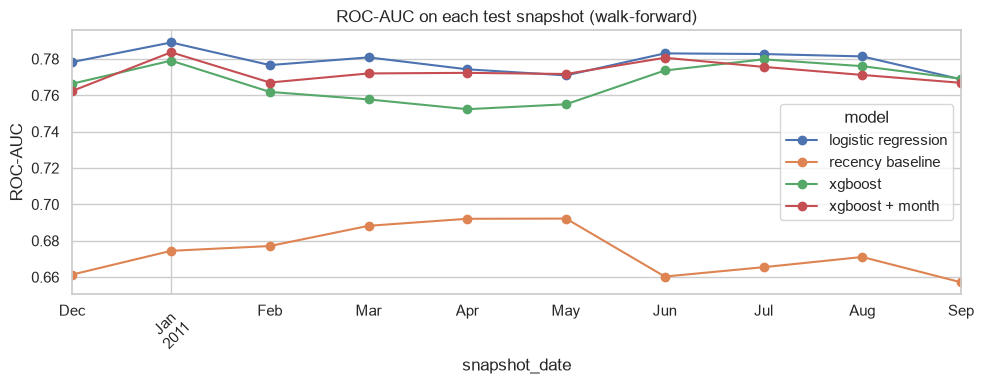

In [2]:
pivot = results.pivot(index="snapshot_date", columns="model", values="roc_auc")
ax = pivot.plot(marker="o", figsize=(10, 4))
ax.set_title("ROC-AUC on each test snapshot (walk-forward)")
ax.set_ylabel("ROC-AUC")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

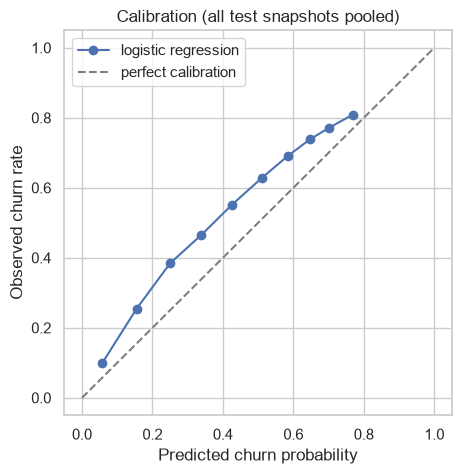

In [3]:
lr = preds[preds["model"] == "logistic regression"].copy()
frac_pos, mean_pred = calibration_curve(lr["churned"], lr["score"], n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(mean_pred, frac_pos, marker="o", label="logistic regression")
ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
ax.set_xlabel("Predicted churn probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration (all test snapshots pooled)")
ax.legend()
plt.show()

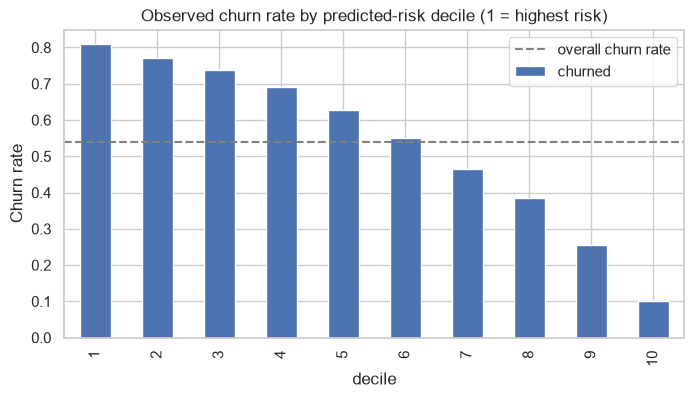

decile
1     0.809
2     0.771
3     0.738
4     0.692
5     0.627
6     0.550
7     0.465
8     0.384
9     0.254
10    0.100
Name: churned, dtype: float64

In [4]:
lr["decile"] = pd.qcut(lr["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
by_decile = lr.groupby("decile", observed=True)["churned"].mean()

ax = by_decile.plot(kind="bar", figsize=(8, 4))
ax.axhline(lr["churned"].mean(), color="gray", linestyle="--", label="overall churn rate")
ax.set_title("Observed churn rate by predicted-risk decile (1 = highest risk)")
ax.set_ylabel("Churn rate")
ax.legend()
plt.show()
by_decile.round(3)

In [5]:
lr = preds[preds["model"] == "logistic regression"]
check = lr.groupby("snapshot_date").agg(
    mean_predicted=("score", "mean"),
    observed_churn=("churned", "mean"),
)
check["gap"] = check["observed_churn"] - check["mean_predicted"]
check["train_churn_rate"] = [
    data[data["snapshot_date"] <= d - pd.Timedelta(days=90)]["churned"].mean()
    for d in check.index
]
check.round(3)

,mean_predicted,observed_churn,gap,train_churn_rate
snapshot_date,,,,
2010-12-01,0.387,0.620,0.233,0.449
2011-01-01,0.373,0.623,0.250,0.443
2011-02-01,0.400,0.603,0.204,0.455
2011-03-01,0.448,0.576,0.128,0.483
2011-04-01,0.483,0.561,0.078,0.502
2011-05-01,0.473,0.522,0.049,0.502
2011-06-01,0.475,0.500,0.025,0.522
2011-07-01,0.475,0.484,0.009,0.525
2011-08-01,0.476,0.443,-0.032,0.525


## Findings
- Walk-forward evaluation: each month is scored by a model trained only on snapshots whose outcome was already known. 10 test snapshots, Dec 2010 to Sep 2011.
- Every model beats the recency baseline (ROC-AUC 0.674) in every test month. Logistic regression is best on average (ROC-AUC 0.779, Brier 0.207), ahead of XGBoost (0.767). With 16 features the signal is mostly linear, so the simpler model wins. Adding snapshot month recovers part of XGBoost's gap (0.772).
- Risk ranking works: the highest-risk decile churned at 81%, the lowest at 10%, against 54% overall.
- Calibration depends on the season. Pooled over all test months the model under-predicts churn, but month by month the error flips sign: predictions were 23 to 25 points too low for the Dec 2010 and Jan 2011 snapshots (the post-holiday lull) and 3 to 8 points too high for Aug and Sep 2011. Mean predicted churn stays near 47% from April on, while observed churn falls from 56% to 39%. The model ranks customers reliably (ROC-AUC stable at 0.77 to 0.79) but does not know the base rate of the coming 90 days, which is driven by season. Raw probabilities should not be used as absolute churn estimates. Part 8 uses rank-based targeting and base-rate scenarios instead.